# 01 · Caso de uso, muestreo y partición de datos
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `00_base.parquet` (del notebook 00) · **Salida:** `01_train`, `01_test`, modelo de
segmentación, reporte de segmentos.

Este notebook hace tres cosas y las hace **una sola vez para todo el proyecto**:
1. Presenta el **caso de uso** y define qué predecimos (y qué NO).
2. **Segmenta** la cartera con un modelo de clustering.
3. **Parte** train/test estratificando por `segmento × target`, y demuestra por qué.

## 1.0 El caso de uso

<img src='https://datahack-prod.s3.ap-south-1.amazonaws.com/__sized__/contest_cover/loanpre-thumbnail-1200x1200.png' width='300'>

Una entidad financiera quiere **automatizar la elegibilidad crediticia** en tiempo real, a
partir del formulario de solicitud online. **Pregunta de negocio:** dado un solicitante nuevo,
¿aprobamos o rechazamos su crédito?

### Diccionario de datos

| Variable | Descripción | Tipo |
|---|---|---|
| `Gender`, `Married`, `Education`, `Self_Employed` | Demográficas | Categórica nominal |
| `Dependents` | N° de dependientes (0,1,2,3+) | Categórica **ordinal** |
| `ApplicantIncome`, `CoapplicantIncome` | Ingresos | Numérica continua |
| `LoanAmount` | Monto del crédito (miles) | Numérica |
| `Loan_Amount_Term` | Plazo (meses) | Numérica |
| `Credit_History` | Cumple normativa de historial (0/1) | **Binaria** |
| `Property_Area` | Zona (Urban/Semiurban/Rural) | Categórica nominal |
| `Loan_Status` | **TARGET** — 1 = rechazado | Binaria |

## 1.1 ⚠️ Reflexión crítica: ¿qué predecimos realmente?

**El punto más importante del proyecto, y casi nunca se enseña.**

`Loan_Status` **no** es si el cliente pagó. Es **la decisión que tomó el banco**. Un modelo
entrenado sobre esta variable **no aprende quién es riesgoso**: aprende a **replicar las
decisiones del comité de crédito**, incluidos sus sesgos.

- **Perpetúa sesgos:** si el comité rechazó más a ciertos perfiles, el modelo lo hará a escala,
  con apariencia de objetividad. `Gender`/`Married` en un modelo de crédito son un riesgo
  regulatorio serio (a menudo ilegal).
- **Sesgo de selección:** solo vemos el resultado de los créditos **aprobados**. De los
  rechazados nunca sabremos si habrían pagado.
- **`Credit_History` domina:** lo veremos en cada etapa. No es una relación descubierta — es la
  **regla del propio comité**. El modelo hace ingeniería inversa de una política.

> 🎓 **Definir bien el target es el 80% del proyecto.** La pregunta antes de escribir código:
> *¿la variable que tengo responde la pregunta de negocio que me hicieron?* Aquí, con matices.
> Seguimos con plena conciencia de la limitación.

## 1.2 Carga de la base y preámbulo

Cargamos `00_base` y creamos un par de alias (`seed`, `target`, `data_creditos`) para que el
código de esta sesión lea natural.

In [26]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    SEED, TARGET, SEGMENT_COL, load_stage, save_stage,
    save_artifact, save_report, save_table, set_plot_theme,
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

set_plot_theme()
np.random.seed(SEED)

# Alias para legibilidad
seed = SEED
target = TARGET
data_creditos = load_stage("00_base")

print("Base cargada:", data_creditos.shape)
print("Tasa de evento:", f"{data_creditos[target].mean():.2%}")
data_creditos.head()

Base cargada: (614, 12)
Tasa de evento: 31.27%


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,0
LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,1
LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,0
LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,0
LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,0


---
# 2. Muestreo y partición

## 2.1 La pregunta que casi nadie se hace

Todo el mundo escribe `train_test_split(X, y, stratify=y)`. Eso garantiza que la **tasa de
evento** sea igual en train y test. Perfecto. **¿Y todo lo demás?**

Tu cartera no es una masa homogénea: tiene **segmentos** con comportamientos distintos. Si el
azar los reparte mal, entrenas con una cartera y evalúas con otra — y `stratify=y` **no te
protege de eso** (lo demostramos en 2.5). Lo hacemos en tres pasos: **segmentar → estratificar
por segmento × target → comparar**.

## 2.2 Separación de features (X) y target (y)

In [27]:
X = data_creditos.drop(target, axis=1)
y = data_creditos[target]

print('X (features):', X.shape)
print('y (target)  :', y.shape)

X (features): (614, 11)
y (target)  : (614,)


In [28]:
X.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
Loan_ID,,,,,,,,,,,
LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban
LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural
LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban
LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban
LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban


In [29]:
y.head()

Loan_ID
LP001002    0
LP001003    1
LP001005    0
LP001006    0
LP001008    0
Name: Loan_Status, dtype: int64

---
## 2.3 Segmentación rápida de la cartera (muestreo por conglomerados)

Un **conglomerado** (o *cluster*) es un grupo natural dentro de la población. En el muestreo
clásico, los conglomerados suelen ser geográficos (sucursales, distritos) porque son los que
vienen dados. Pero en banca hay una opción mucho mejor: **construirlos con un modelo**.

> **La idea:** en vez de usar una variable arbitraria (`Property_Area`) como si fuera un
> conglomerado, dejamos que un algoritmo **no supervisado** encuentre los grupos de clientes
> que de verdad se comportan parecido. Eso es un **modelo de segmentación**, y es lo que un
> área de Analytics tiene corriendo sobre su cartera todo el tiempo.

Usaremos **K-Means**: agrupa observaciones minimizando la distancia de cada punto al centro
de su grupo.

### ⚠️ Dos advertencias antes de tocar el código

**1. K-Means usa DISTANCIAS. Sin escalar, no funciona.**
Si `ApplicantIncome` va en miles y `Dependents` en unidades, la distancia euclidiana es,
literalmente, la diferencia de ingresos: el resto de variables no existe. Por eso escalamos
**siempre** antes de cualquier modelo no supervisado.

**2. ¿Esto es leakage? NO — y entender por qué es importante.**
Vamos a ajustar el K-Means sobre el dataset **completo**, antes del split. Suena a pecado,
pero no lo es, por la misma razón por la que `stratify=y` tampoco lo es: **el segmento no
entra al modelo como feature**. Es un instrumento de **diseño muestral** — sirve para decidir
*qué fila va a train y cuál a test*, y ahí se acaba su trabajo.

> 🔴 **Dónde sí sería leakage:** si decidieras usar `Segmento` como **variable predictora**.
> En ese caso el K-Means tendría que ajustarse **solo con train** y aplicarse con `.predict()`
> al test, exactamente igual que el imputer o el scaler. **En este notebook no lo usamos como
> feature**, y por eso podemos ajustarlo sobre todo el dataset con la conciencia tranquila.

La distinción a memorizar es:

| Uso del segmento | ¿Se puede ajustar sobre todo el dataset? |
|---|---|
| **Diseño muestral** (decidir la partición) | ✅ Sí — igual que `stratify=y` |
| **Feature del modelo** (predecir con él) | ❌ No — `fit` solo en train |

### Paso 1: preprocesamiento mínimo (solo para segmentar)

El K-Means no admite nulos y necesita escala común. Como todavía no hemos preprocesado nada,
hacemos aquí una versión **mínima y local**, que no contamina el pipeline oficial de la
sección 6.

In [30]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Variables de COMPORTAMIENTO FINANCIERO. Ojo: deliberadamente NO usamos Gender, Married
# ni Education. Segmentar por variables demográficas protegidas replicaría sesgos
# sociales en la estructura misma de la partición (ver sección 1.3).
vars_segmentacion = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

X_seg = X[vars_segmentacion].copy()
X_seg['TotalIncome'] = X_seg['ApplicantIncome'] + X_seg['CoapplicantIncome']

# Imputación simple (mediana) — solo para poder calcular distancias
X_seg = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(X_seg),
    columns=X_seg.columns, index=X_seg.index
)

# log1p para domar las colas: sin esto, un solicitante millonario forma su propio
# "segmento" de una persona y el clustering se vuelve inútil.
for c in ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'TotalIncome']:
    X_seg[c] = np.log1p(X_seg[c])

# Estandarización: OBLIGATORIA antes de K-Means
Z_seg = StandardScaler().fit_transform(X_seg)

print('Matriz para segmentar:', Z_seg.shape)
print('Variables:', list(X_seg.columns))

Matriz para segmentar: (614, 5)
Variables: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'TotalIncome']


### Paso 2: ¿cuántos segmentos? El coeficiente de silueta

El **silhouette score** mide qué tan bien separados están los grupos: va de −1 a 1, y cuanto
más alto, mejor definidos están. Lo usamos para elegir `k` con un criterio numérico en vez
de a ojo.

In [31]:
resultados_k = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(Z_seg)
    resultados_k.append({
        'k': k,
        'silhouette': silhouette_score(Z_seg, km.labels_),
        'inercia': km.inertia_,
        'tamaño_min': np.bincount(km.labels_).min(),
    })

tabla_k = pd.DataFrame(resultados_k)
tabla_k['silhouette'] = tabla_k['silhouette'].round(4)
tabla_k['inercia'] = tabla_k['inercia'].round(1)
print(tabla_k.to_string(index=False))

k_optimo = int(tabla_k.loc[tabla_k['silhouette'].idxmax(), 'k'])
print()
print(f'>> k óptimo por silhouette: {k_optimo}')
print()
print('   Nota: el silhouette no es lo único que importa. Un k con silhouette altísimo')
print('   pero un segmento de 3 clientes es inútil para estratificar (no se puede partir')
print('   80/20 un grupo de 3). Mira siempre la columna tamaño_min.')

 k  silhouette  inercia  tamaño_min
 2      0.3131   2237.4         178
 3      0.3559   1704.2         112
 4      0.3977   1297.5          56
 5      0.3721   1125.4          54
 6      0.3531    975.0          34

>> k óptimo por silhouette: 4

   Nota: el silhouette no es lo único que importa. Un k con silhouette altísimo
   pero un segmento de 3 clientes es inútil para estratificar (no se puede partir
   80/20 un grupo de 3). Mira siempre la columna tamaño_min.


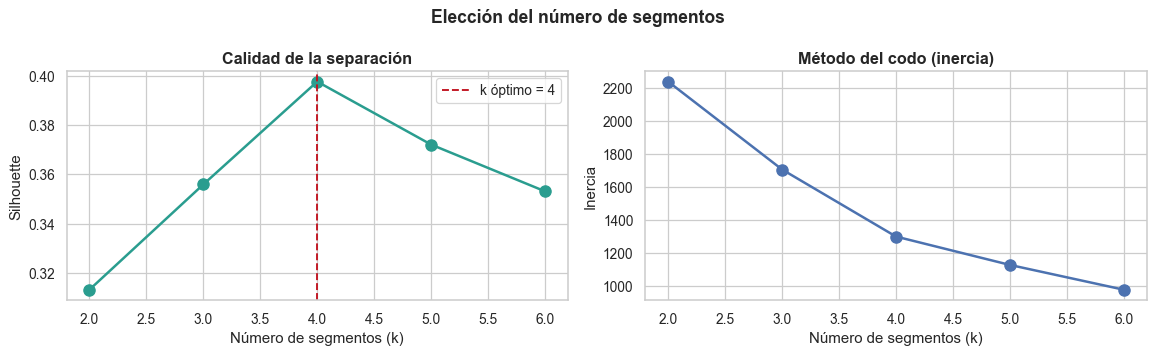

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(tabla_k['k'], tabla_k['silhouette'], 'o-', color='#2a9d8f', lw=2, ms=9)
axes[0].axvline(k_optimo, color='#c1121f', ls='--', label=f'k óptimo = {k_optimo}')
axes[0].set_xlabel('Número de segmentos (k)'); axes[0].set_ylabel('Silhouette')
axes[0].set_title('Calidad de la separación'); axes[0].legend()

axes[1].plot(tabla_k['k'], tabla_k['inercia'], 'o-', color='#4c72b0', lw=2, ms=9)
axes[1].set_xlabel('Número de segmentos (k)'); axes[1].set_ylabel('Inercia')
axes[1].set_title('Método del codo (inercia)')
plt.suptitle('Elección del número de segmentos', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Paso 3: el modelo de segmentación

In [33]:
kmeans = KMeans(n_clusters=k_optimo, random_state=seed, n_init=10)
segmento = pd.Series(kmeans.fit_predict(Z_seg), index=X.index, name='Segmento')

print(f'Segmentos creados: {k_optimo}')
print()
print(segmento.value_counts().sort_index().to_frame('n_clientes'))

Segmentos creados: 4

          n_clientes
Segmento            
0                274
1                106
2                178
3                 56


### Paso 4: perfilar los segmentos — el trabajo que sí importa

Un clustering sin interpretar es un número de grupo sin significado. **El valor está aquí:**
traducir "segmento 2" a algo que un gerente comercial reconozca.

In [34]:
perfil = X[vars_segmentacion].copy()
perfil['TotalIncome'] = perfil['ApplicantIncome'] + perfil['CoapplicantIncome']

tabla_perfil = perfil.groupby(segmento).median()
tabla_perfil['n'] = segmento.value_counts().sort_index()
tabla_perfil['%_cartera'] = (segmento.value_counts(normalize=True).sort_index() * 100).round(1)
tabla_perfil['%_con_coaplicante'] = (X['CoapplicantIncome'].gt(0).groupby(segmento).mean() * 100).round(1)
tabla_perfil['tasa_rechazo_%'] = (y.groupby(segmento).mean() * 100).round(1)

print('PERFIL DE LOS SEGMENTOS (medianas)')
print('=' * 110)
print(tabla_perfil.round(1).to_string())
print('=' * 110)

PERFIL DE LOS SEGMENTOS (medianas)
          ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  TotalIncome    n  %_cartera  %_con_coaplicante  tasa_rechazo_%
Segmento                                                                                                                                  
0                  3101.5             2083.0       128.0             360.0       5359.5  274       44.6              100.0            25.5
1                  9833.0                0.0       240.0             360.0      11198.0  106       17.3               34.0            33.0
2                  4146.5                0.0       107.5             360.0       4146.5  178       29.0                0.6            38.2
3                  3643.5              918.0       115.5             180.0       5597.0   56        9.1               53.6            33.9


In [35]:
# Le ponemos nombre de negocio a cada segmento a partir de lo que muestra el perfil.
# Esto NO es cosmético: un segmento sin nombre no se puede accionar comercialmente.
nombres_segmento = {}
for s in tabla_perfil.index:
    fila = tabla_perfil.loc[s]
    if fila['Loan_Amount_Term'] < 300:
        nombres_segmento[s] = 'Plazo corto'
    elif fila['%_con_coaplicante'] > 80:
        nombres_segmento[s] = 'Hogar doble ingreso'
    elif fila['TotalIncome'] > perfil['TotalIncome'].median() * 1.8:
        nombres_segmento[s] = 'Alto ingreso / préstamo grande'
    else:
        nombres_segmento[s] = 'Solicitante único'

print('SEGMENTOS IDENTIFICADOS:')
print()
for s, nombre in nombres_segmento.items():
    f = tabla_perfil.loc[s]
    print(f'  Segmento {s} — "{nombre}"')
    print(f'      {int(f["n"])} clientes ({f["%_cartera"]}% de la cartera) | '
          f'tasa de rechazo {f["tasa_rechazo_%"]}%')
    print(f'      Ingreso total mediano: {f["TotalIncome"]:,.0f} | '
          f'Préstamo: {f["LoanAmount"]:,.0f} | Plazo: {f["Loan_Amount_Term"]:.0f} meses')
    print()

spread = tabla_perfil['tasa_rechazo_%'].max() - tabla_perfil['tasa_rechazo_%'].min()
print('=' * 70)
print(f'Tasa de rechazo: de {tabla_perfil["tasa_rechazo_%"].min()}% a '
      f'{tabla_perfil["tasa_rechazo_%"].max()}%  →  spread de {spread:.1f} puntos porcentuales')
print()
print('>> ESTE número es el que justifica todo lo que viene. Los segmentos NO son')
print('   intercambiables: tienen riesgo distinto. Si el azar mete de más un segmento')
print('   en el test, la tasa de evento del test se mueve por una razón que no tiene')
print('   nada que ver con el modelo. Por eso vale la pena estratificar por segmento.')
print('=' * 70)

SEGMENTOS IDENTIFICADOS:

  Segmento 0 — "Hogar doble ingreso"
      274 clientes (44.6% de la cartera) | tasa de rechazo 25.5%
      Ingreso total mediano: 5,360 | Préstamo: 128 | Plazo: 360 meses

  Segmento 1 — "Alto ingreso / préstamo grande"
      106 clientes (17.3% de la cartera) | tasa de rechazo 33.0%
      Ingreso total mediano: 11,198 | Préstamo: 240 | Plazo: 360 meses

  Segmento 2 — "Solicitante único"
      178 clientes (29.0% de la cartera) | tasa de rechazo 38.2%
      Ingreso total mediano: 4,146 | Préstamo: 108 | Plazo: 360 meses

  Segmento 3 — "Plazo corto"
      56 clientes (9.1% de la cartera) | tasa de rechazo 33.9%
      Ingreso total mediano: 5,597 | Préstamo: 116 | Plazo: 180 meses

Tasa de rechazo: de 25.5% a 38.2%  →  spread de 12.7 puntos porcentuales

>> ESTE número es el que justifica todo lo que viene. Los segmentos NO son
   intercambiables: tienen riesgo distinto. Si el azar mete de más un segmento
   en el test, la tasa de evento del test se mueve por

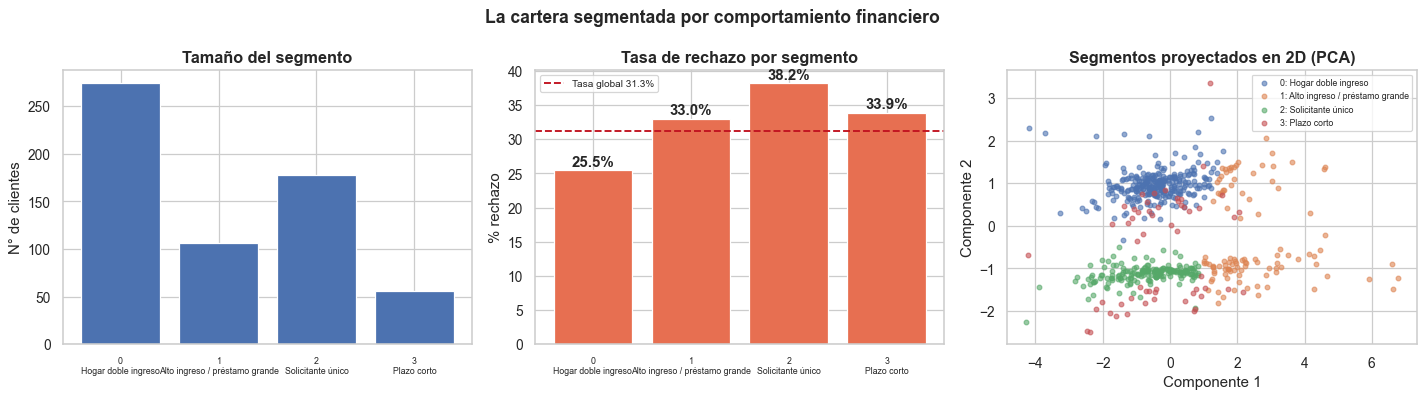

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Tamaño de cada segmento
etiquetas = [f'{s}\n{nombres_segmento[s]}' for s in tabla_perfil.index]
axes[0].bar(etiquetas, tabla_perfil['n'], color='#4c72b0')
axes[0].set_title('Tamaño del segmento')
axes[0].set_ylabel('N° de clientes')
axes[0].tick_params(axis='x', labelsize=7)

# Tasa de rechazo por segmento
barras = axes[1].bar(etiquetas, tabla_perfil['tasa_rechazo_%'], color='#e76f51')
axes[1].axhline(y.mean() * 100, color='#c1121f', ls='--', lw=1.5,
                label=f'Tasa global {y.mean():.1%}')
for b, v in zip(barras, tabla_perfil['tasa_rechazo_%']):
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.6, f'{v}%', ha='center', fontweight='bold')
axes[1].set_title('Tasa de rechazo por segmento')
axes[1].set_ylabel('% rechazo')
axes[1].tick_params(axis='x', labelsize=7)
axes[1].legend(fontsize=8)

# Proyección 2D de los segmentos
from sklearn.decomposition import PCA as _PCA
proy = _PCA(n_components=2, random_state=seed).fit_transform(Z_seg)
for s in sorted(segmento.unique()):
    m = segmento.values == s
    axes[2].scatter(proy[m, 0], proy[m, 1], s=14, alpha=0.6, label=f'{s}: {nombres_segmento[s]}')
axes[2].set_title('Segmentos proyectados en 2D (PCA)')
axes[2].set_xlabel('Componente 1'); axes[2].set_ylabel('Componente 2')
axes[2].legend(fontsize=7)

plt.suptitle('La cartera segmentada por comportamiento financiero', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 2.4 La partición estratificada por segmento × target

Ya tenemos los conglomerados. Ahora construimos la **llave de estratificación**: queremos
preservar **dos** cosas a la vez en train y test:

1. La **tasa de evento** (target) → lo que hace el `stratify=y` de siempre
2. La **composición de segmentos** (la estructura de la cartera) → lo que casi nadie hace

La solución es cruzar ambas en una sola llave: `segmento × target`.

In [37]:
llave_estrato = segmento.astype(str) + '_' + y.astype(str)
llave_estrato.name = 'Estrato'

print(f'Estratos generados: {llave_estrato.nunique()}  ({k_optimo} segmentos × 2 clases del target)')
print()
conteo = llave_estrato.value_counts().sort_index()
tabla_estratos = conteo.to_frame('n')
tabla_estratos['segmento'] = [nombres_segmento[int(i.split('_')[0])] for i in tabla_estratos.index]
tabla_estratos['target'] = ['Aprobado' if i.endswith('_0') else 'RECHAZADO' for i in tabla_estratos.index]
tabla_estratos['en_test_(20%)'] = (tabla_estratos['n'] * 0.2).round().astype(int)
print(tabla_estratos.to_string())

Estratos generados: 8  (4 segmentos × 2 clases del target)

           n                        segmento     target  en_test_(20%)
Estrato                                                               
0_0      204             Hogar doble ingreso   Aprobado             41
0_1       70             Hogar doble ingreso  RECHAZADO             14
1_0       71  Alto ingreso / préstamo grande   Aprobado             14
1_1       35  Alto ingreso / préstamo grande  RECHAZADO              7
2_0      110               Solicitante único   Aprobado             22
2_1       68               Solicitante único  RECHAZADO             14
3_0       37                     Plazo corto   Aprobado              7
3_1       19                     Plazo corto  RECHAZADO              4


### ⚠️ La verificación que evita el error más común de la estratificación

`train_test_split` **falla** si algún estrato tiene menos de 2 miembros: no puede poner una
fila en train y otra en test si solo hay una. Y con `k` grande esto pasa enseguida —
es la razón por la que mucha gente abandona la estratificación fina y vuelve al `stratify=y`.

**La regla práctica:** cada estrato necesita al menos unos 10 casos para que el test reciba
2 y la estimación no sea puro ruido.

In [38]:
min_estrato = conteo.min()
print(f'Estrato más pequeño: {conteo.idxmin()} con {min_estrato} casos')
print(f'  → en el test le tocarían ~{round(min_estrato * 0.2)} clientes')
print()

if min_estrato < 2:
    print('❌ IMPOSIBLE estratificar: hay estratos con menos de 2 casos.')
    print('   Solución: reducir k, o colapsar los segmentos pequeños en uno de "Otros".')
elif min_estrato < 10:
    print('⚠️  Se puede estratificar, pero hay estratos muy pequeños.')
    print('   Las métricas sobre esos grupos tendrán muchísima varianza.')
else:
    print('✅ Todos los estratos tienen tamaño suficiente para partir 80/20.')

assert min_estrato >= 2, 'Hay estratos con menos de 2 miembros: train_test_split fallará'

Estrato más pequeño: 3_1 con 19 casos
  → en el test le tocarían ~4 clientes

✅ Todos los estratos tienen tamaño suficiente para partir 80/20.


### El split definitivo

Documentación: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

| Parámetro | Por qué |
|---|---|
| `test_size=0.2` | Reserva el 20% para evaluación |
| `stratify=llave_estrato` | ⭐ Preserva **tasa de evento Y composición de segmentos** |
| `random_state=seed` | **Reproducibilidad**: la misma partición siempre |

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=llave_estrato,   # ⭐ segmento × target, no solo el target
    random_state=seed
)

# Guardamos a qué segmento pertenece cada fila, para poder auditar la partición.
# OJO: `segmento` NO es una feature del modelo — es un instrumento de diseño muestral.
# No se añade a X_train ni a X_test.
seg_train = segmento.loc[X_train.index]
seg_test = segmento.loc[X_test.index]

print('X_train:', X_train.shape, ' | X_test:', X_test.shape)
print('y_train:', y_train.shape, ' | y_test:', y_test.shape)
print()
print('Columnas de X_train:', list(X_train.columns))
print()
print('>> Nota que "Segmento" NO está entre las columnas. Cumplió su función')
print('   (decidir la partición) y sale de escena. Si lo dejáramos entrar al modelo,')
print('   tendríamos que reajustar el K-Means solo con train.')

X_train: (491, 11)  | X_test: (123, 11)
y_train: (491,)  | y_test: (123,)

Columnas de X_train: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

>> Nota que "Segmento" NO está entre las columnas. Cumplió su función
   (decidir la partición) y sale de escena. Si lo dejáramos entrar al modelo,
   tendríamos que reajustar el K-Means solo con train.


### Validación de la partición

**Nunca confíes en un split sin verificarlo.** Estas líneas han salvado más proyectos
que cualquier algoritmo.

In [40]:
resumen = pd.DataFrame({
    'n_filas': [len(y), len(y_train), len(y_test)],
    '%_del_total': [1.0, len(y_train)/len(y), len(y_test)/len(y)],
    'n_rechazos': [y.sum(), y_train.sum(), y_test.sum()],
    'tasa_evento': [y.mean(), y_train.mean(), y_test.mean()],
}, index=['TOTAL', 'TRAIN', 'TEST'])
resumen['%_del_total'] = resumen['%_del_total'].map('{:.1%}'.format)
resumen['tasa_evento'] = resumen['tasa_evento'].map('{:.2%}'.format)
print('--- Dimensión 1: la tasa de evento ---')
print(resumen)

--- Dimensión 1: la tasa de evento ---
       n_filas %_del_total  n_rechazos tasa_evento
TOTAL      614      100.0%         192      31.27%
TRAIN      491       80.0%         153      31.16%
TEST       123       20.0%          39      31.71%


In [41]:
comp = pd.DataFrame({
    'TOTAL_%': segmento.value_counts(normalize=True).sort_index() * 100,
    'TRAIN_%': seg_train.value_counts(normalize=True).sort_index() * 100,
    'TEST_%': seg_test.value_counts(normalize=True).sort_index() * 100,
})
comp['segmento'] = [nombres_segmento[i] for i in comp.index]
comp['dif_train_test_pp'] = (comp['TRAIN_%'] - comp['TEST_%']).abs()

print('--- Dimensión 2: la composición de la cartera ---')
print(comp.round(2).to_string())
print()
print(f'Desviación máxima entre train y test: {comp["dif_train_test_pp"].max():.2f} puntos porcentuales')
print()
print('>> Ambas dimensiones preservadas a la vez. Eso es lo que compramos con la llave')
print('   compuesta. En la sección 2.5 veremos cuánto cuesta NO hacerlo.')

--- Dimensión 2: la composición de la cartera ---
          TOTAL_%  TRAIN_%  TEST_%                        segmento  dif_train_test_pp
Segmento                                                                             
0           44.63    44.60   44.72             Hogar doble ingreso               0.11
1           17.26    17.31   17.07  Alto ingreso / préstamo grande               0.24
2           28.99    28.92   29.27               Solicitante único               0.35
3            9.12     9.16    8.94                     Plazo corto               0.22

Desviación máxima entre train y test: 0.35 puntos porcentuales

>> Ambas dimensiones preservadas a la vez. Eso es lo que compramos con la llave
   compuesta. En la sección 2.5 veremos cuánto cuesta NO hacerlo.


In [42]:
# Verificaciones de integridad — parte de tu checklist SIEMPRE.
print('¿Hay solapamiento entre train y test?',
      len(set(X_train.index) & set(X_test.index)), 'filas compartidas')
print('¿Train + test = total?', len(X_train) + len(X_test) == len(X))
print('¿Índices de X_train e y_train alineados?', X_train.index.equals(y_train.index))
print('¿Índices de X_test e y_test alineados?', X_test.index.equals(y_test.index))

assert len(set(X_train.index) & set(X_test.index)) == 0, 'FUGA: filas compartidas entre train y test'
assert len(X_train) + len(X_test) == len(X)
print('\n✅ Partición válida.')

¿Hay solapamiento entre train y test? 0 filas compartidas
¿Train + test = total? True
¿Índices de X_train e y_train alineados? True
¿Índices de X_test e y_test alineados? True

✅ Partición válida.


---
## 2.5 La comparativa: ¿qué pasa si NO estratificas?

Hasta aquí todo son afirmaciones. Vamos a medirlas.

Comparamos **tres diseños de partición** sobre el mismo dataset:

| Diseño | Código | Qué promete preservar |
|---|---|---|
| **A. Sin estratificar** | `stratify=None` | Nada. Azar puro |
| **B. Estratificado por target** | `stratify=y` | La tasa de evento |
| **C. Estratificado por segmento × target** | `stratify=llave_estrato` | Tasa de evento **y** composición |

### La foto: una sola partición

Empezamos mirando **una** partición de cada tipo, con la misma semilla.

In [43]:
def evaluar_particion(strat, nombre, random_state=seed):
    """Parte el dataset y mide cuánto se desvían train y test en las dos dimensiones."""
    idx_tr, idx_te = train_test_split(np.asarray(X.index, dtype=object), test_size=0.2,
                                      stratify=strat, random_state=random_state)
    # Dimensión 1: tasa de evento
    dif_target = abs(y.loc[idx_tr].mean() - y.loc[idx_te].mean()) * 100
    # Dimensión 2: composición de segmentos
    c_tr = segmento.loc[idx_tr].value_counts(normalize=True).sort_index()
    c_te = segmento.loc[idx_te].value_counts(normalize=True).sort_index()
    dif_seg = (c_tr - c_te).abs().max() * 100
    return {'Diseño': nombre,
            'Desv. tasa evento (pp)': round(dif_target, 2),
            'Desv. máx. segmentos (pp)': round(dif_seg, 2)}

foto = pd.DataFrame([
    evaluar_particion(None, 'A. Sin estratificar'),
    evaluar_particion(y, 'B. Estratificado por target'),
    evaluar_particion(llave_estrato, 'C. Estratificado por segmento × target'),
])
print('UNA partición de cada tipo (semilla =', seed, ')')
print('=' * 84)
print(foto.to_string(index=False))
print('=' * 84)
print()
print('>> Con UNA sola semilla el resultado no prueba nada: pudo ser suerte.')
print('   Un buen resultado aquí puede ser casualidad, y uno malo también.')
print('   La única forma honesta de comparar diseños muestrales es REPETIR.')

UNA partición de cada tipo (semilla = 2021 )
                                Diseño  Desv. tasa evento (pp)  Desv. máx. segmentos (pp)
                   A. Sin estratificar                    4.61                       2.15
           B. Estratificado por target                    0.47                       2.27
C. Estratificado por segmento × target                    0.55                       0.35

>> Con UNA sola semilla el resultado no prueba nada: pudo ser suerte.
   Un buen resultado aquí puede ser casualidad, y uno malo también.
   La única forma honesta de comparar diseños muestrales es REPETIR.


### La película: 200 particiones de cada tipo

Repetimos el experimento con 200 semillas distintas. Esto ya no es una anécdota:
es la **distribución** del error de cada diseño.

In [44]:
n_reps = 200
registro = {'A. Sin estratificar': [],
            'B. Estratificado por target': [],
            'C. Estratificado por segmento × target': []}

for s in range(n_reps):
    for nombre, strat in [('A. Sin estratificar', None),
                          ('B. Estratificado por target', y),
                          ('C. Estratificado por segmento × target', llave_estrato)]:
        r = evaluar_particion(strat, nombre, random_state=s)
        registro[nombre].append((r['Desv. tasa evento (pp)'], r['Desv. máx. segmentos (pp)']))

filas = []
for nombre, vals in registro.items():
    a = np.array(vals)
    filas.append({
        'Diseño': nombre,
        'TARGET media': round(a[:, 0].mean(), 2),
        'TARGET p95': round(np.percentile(a[:, 0], 95), 2),
        'TARGET peor': round(a[:, 0].max(), 2),
        'SEGMENTOS media': round(a[:, 1].mean(), 2),
        'SEGMENTOS p95': round(np.percentile(a[:, 1], 95), 2),
        'SEGMENTOS peor': round(a[:, 1].max(), 2),
    })

comparativa = pd.DataFrame(filas)
print(f'DESVIACIÓN TRAIN vs TEST en {n_reps} particiones (en puntos porcentuales)')
print('=' * 108)
print(comparativa.to_string(index=False))
print('=' * 108)

DESVIACIÓN TRAIN vs TEST en 200 particiones (en puntos porcentuales)
                                Diseño  TARGET media  TARGET p95  TARGET peor  SEGMENTOS media  SEGMENTOS p95  SEGMENTOS peor
                   A. Sin estratificar          3.99        8.73        12.75             5.33           9.83           14.12
           B. Estratificado por target          0.47        0.47         0.47             6.02          10.85           14.12
C. Estratificado por segmento × target          0.55        0.55         0.55             0.35           0.35            0.35


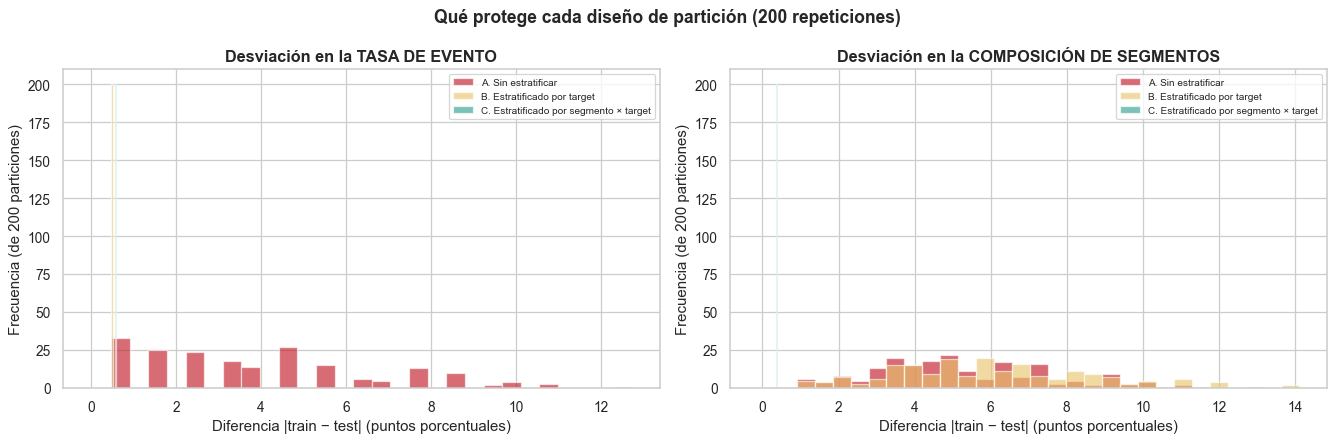

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colores = {'A. Sin estratificar': '#c1121f',
           'B. Estratificado por target': '#e9c46a',
           'C. Estratificado por segmento × target': '#2a9d8f'}

for j, (titulo, idx) in enumerate([('Desviación en la TASA DE EVENTO', 0),
                                   ('Desviación en la COMPOSICIÓN DE SEGMENTOS', 1)]):
    for nombre, vals in registro.items():
        a = np.array(vals)[:, idx]
        axes[j].hist(a, bins=28, alpha=0.62, label=nombre, color=colores[nombre])
    axes[j].set_title(titulo)
    axes[j].set_xlabel('Diferencia |train − test| (puntos porcentuales)')
    axes[j].set_ylabel(f'Frecuencia (de {n_reps} particiones)')
    axes[j].legend(fontsize=8)

plt.suptitle(f'Qué protege cada diseño de partición ({n_reps} repeticiones)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 📊 Cómo se lee este gráfico (es el corazón de la sección)

**Panel izquierdo — la tasa de evento:**
- **Sin estratificar** (rojo): la distribución se extiende hacia la derecha. Hay particiones
  donde train y test difieren varios puntos porcentuales **solo por azar**.
- **B y C** (amarillo y verde): colapsan casi en una barra pegada al cero. Ambos cumplen
  lo que prometen.

**Panel derecho — la composición de segmentos. Aquí está la sorpresa:**
- **B, el `stratify=y` de toda la vida, se comporta igual de mal que no estratificar.**
  Su distribución está encima de la roja.
- Solo **C** (verde) colapsa contra el cero.

> 🎓 **La lección:** `stratify=y` **no** es "estratificar". Es "estratificar **por el
> target**". Protege exactamente esa dimensión y **ninguna otra**. Si tu cartera tiene
> estructura y esa estructura te importa, tienes que decírselo explícitamente al split.
> El azar no reparte los segmentos por ti.

In [46]:
peor_B = comparativa.loc[comparativa['Diseño'].str.startswith('B'), 'SEGMENTOS peor'].iloc[0]
peor_C = comparativa.loc[comparativa['Diseño'].str.startswith('C'), 'SEGMENTOS peor'].iloc[0]
med_B = comparativa.loc[comparativa['Diseño'].str.startswith('B'), 'SEGMENTOS media'].iloc[0]
med_C = comparativa.loc[comparativa['Diseño'].str.startswith('C'), 'SEGMENTOS media'].iloc[0]

print('EL NÚMERO QUE HAY QUE LLEVARSE')
print('=' * 72)
print(f'  Desviación en composición de segmentos (peor caso de {n_reps} particiones):')
print(f'      stratify=y                 : {peor_B:5.2f} pp')
print(f'      stratify=segmento × target : {peor_C:5.2f} pp')
print()
print(f'  En promedio: {med_B:.2f} pp  vs  {med_C:.2f} pp')
print('=' * 72)
print()
print('Traducción a negocio: con stratify=y, en el peor caso te puede tocar un test')
print(f'con {peor_B:.0f} puntos porcentuales de más (o de menos) de un segmento entero.')
print('Como cada segmento tiene una tasa de rechazo distinta (spread de',
      f'{spread:.1f} pp — ver 2.3),')
print('tu métrica de test se mueve por la LOTERÍA DE LA PARTICIÓN, no por tu modelo.')
print()
print('Y lo peor: el efecto no es aleatorio entre corridas — es FIJO. Elegiste una')
print('semilla al principio del proyecto y te quedaste con ella. Si esa semilla te dio')
print('una partición sesgada, TODO tu proyecto está construido sobre ella y no lo sabes.')

EL NÚMERO QUE HAY QUE LLEVARSE
  Desviación en composición de segmentos (peor caso de 200 particiones):
      stratify=y                 : 14.12 pp
      stratify=segmento × target :  0.35 pp

  En promedio: 6.02 pp  vs  0.35 pp

Traducción a negocio: con stratify=y, en el peor caso te puede tocar un test
con 14 puntos porcentuales de más (o de menos) de un segmento entero.
Como cada segmento tiene una tasa de rechazo distinta (spread de 12.7 pp — ver 2.3),
tu métrica de test se mueve por la LOTERÍA DE LA PARTICIÓN, no por tu modelo.

Y lo peor: el efecto no es aleatorio entre corridas — es FIJO. Elegiste una
semilla al principio del proyecto y te quedaste con ella. Si esa semilla te dio
una partición sesgada, TODO tu proyecto está construido sobre ella y no lo sabes.


### 🙋 "¿Y por qué segmento y no simplemente la zona (`Property_Area`)?"

Es la pregunta correcta, y merece datos, no una opinión. `Property_Area` ya viene en la tabla,
es gratis y no necesita ningún modelo. Probemos un cuarto diseño: **estratificar por
zona × target**, y midamos las **tres** dimensiones a la vez.

In [47]:
llave_zona = X['Property_Area'].astype(str) + '_' + y.astype(str)

def desviaciones_completas(strat, nombre, n=100):
    """Mide la desviación train/test en las TRES dimensiones, sobre n particiones."""
    d_target, d_seg, d_zona = [], [], []
    for s in range(n):
        itr, ite = train_test_split(np.asarray(X.index, dtype=object), test_size=0.2, stratify=strat, random_state=s)
        d_target.append(abs(y.loc[itr].mean() - y.loc[ite].mean()) * 100)
        a = segmento.loc[itr].value_counts(normalize=True).sort_index()
        b = segmento.loc[ite].value_counts(normalize=True).sort_index()
        d_seg.append((a - b).abs().max() * 100)
        a = X.loc[itr, 'Property_Area'].value_counts(normalize=True).sort_index()
        b = X.loc[ite, 'Property_Area'].value_counts(normalize=True).sort_index()
        d_zona.append((a - b).abs().max() * 100)
    return {'Diseño': nombre,
            'Desv. TARGET': round(np.mean(d_target), 2),
            'Desv. SEGMENTO': round(np.mean(d_seg), 2),
            'Desv. ZONA': round(np.mean(d_zona), 2)}

matriz = pd.DataFrame([
    desviaciones_completas(None, 'A. Sin estratificar'),
    desviaciones_completas(y, 'B. stratify = target'),
    desviaciones_completas(llave_estrato, 'C. stratify = segmento × target'),
    desviaciones_completas(llave_zona, 'D. stratify = zona × target'),
])

print('DESVIACIÓN MEDIA train vs test, en las TRES dimensiones (100 particiones, en pp)')
print('=' * 82)
print(matriz.to_string(index=False))
print('=' * 82)
print()
print('>> LEE ESTA TABLA EN DIAGONAL. Cada diseño protege EXACTAMENTE lo que le pediste,')
print('   y deja las demás dimensiones a merced del azar:')
print()
print('     · B protege el target ......... y abandona segmento y zona')
print('     · C protege segmento y target . y la zona queda al azar')
print('     · D protege zona y target ..... y el segmento queda al azar')
print()
print('   No existe el "estratificar bien" en abstracto. Existe "estratificar POR ALGO".')
print('   La pregunta de diseño no es CÓMO estratificar: es QUÉ necesitas que sea')
print('   comparable entre train y test. Eso lo decide el negocio, no el algoritmo.')

DESVIACIÓN MEDIA train vs test, en las TRES dimensiones (100 particiones, en pp)
                         Diseño  Desv. TARGET  Desv. SEGMENTO  Desv. ZONA
            A. Sin estratificar          4.02            5.45        5.99
           B. stratify = target          0.47            6.18        5.94
C. stratify = segmento × target          0.55            0.35        4.98
    D. stratify = zona × target          0.55            5.86        0.47

>> LEE ESTA TABLA EN DIAGONAL. Cada diseño protege EXACTAMENTE lo que le pediste,
   y deja las demás dimensiones a merced del azar:

     · B protege el target ......... y abandona segmento y zona
     · C protege segmento y target . y la zona queda al azar
     · D protege zona y target ..... y el segmento queda al azar

   No existe el "estratificar bien" en abstracto. Existe "estratificar POR ALGO".
   La pregunta de diseño no es CÓMO estratificar: es QUÉ necesitas que sea
   comparable entre train y test. Eso lo decide el negocio, no el 

### Entonces, ¿zona o segmento?

La tabla muestra que **ambos funcionan** — cada uno para lo suyo. La elección no es técnica,
es de negocio. Nosotros elegimos el **segmento** por tres razones:

1. **Es multivariado.** `Property_Area` es *una* variable; el segmento resume **cinco**
   (ingresos, co-solicitante, monto, plazo) en una sola llave manejable. Proteger el segmento
   protege de paso el perfil financiero completo.

2. **Escala mejor.** Si quisieras proteger zona *y* perfil financiero, la llave
   `zona × segmento × target` daría 24 estratos sobre 614 filas: ~25 casos cada uno,
   y algunos quedarían por debajo del mínimo. El clustering te da esa protección
   multivariada **sin multiplicar los estratos**.

3. **Es accionable.** El área comercial reconoce "Hogar doble ingreso"; nadie diseña una
   campaña para "la intersección de Rural con plazo 180".

> ⚠️ **Y el argumento en contra, que también es válido:** el segmento depende de un modelo
> (K-Means con `k=4`, un preprocesamiento, una semilla). Si mañana reentrenas el clustering,
> los segmentos cambian y tu partición ya no es reproducible. `Property_Area` no tiene ese
> problema: es un dato, no un modelo.
>
> **Por eso, si estratificas por un segmento de clustering, versiona y congela ese modelo
> junto al resto del pipeline.** El `random_state` del K-Means es tan parte de tu
> reproducibilidad como el del split.

### ⚖️ Sé honesto: ¿siempre hay que hacer esto?

**No.** Y decirlo es parte del rigor.

| Situación | Recomendación |
|---|---|
| Dataset grande (>100k) y homogéneo | `stratify=y` basta. El azar promedia bien con volumen |
| Dataset pequeño (como este, 614) | ✅ Estratificar por segmento **sí** aporta |
| Cartera con segmentos de riesgo muy distinto | ✅ Aporta, y mucho |
| Vas a reportar métricas **por segmento** | ✅ **Imprescindible** — si no, unos segmentos casi no aparecen en el test |
| Hay una variable temporal | ⚠️ **Nada de esto aplica**: usa partición **out-of-time** (2.7.5) |

**El costo también existe:** más estratos = estratos más pequeños = más riesgo de que
`train_test_split` falle o de que algún grupo quede con 3 casos en test. La celda de abajo
calcula si tu `k` te deja margen o te deja al borde.

> 🎓 **La regla general:** estratifica por lo que **te importa que sea comparable** entre
> train y test. Si solo te importa la tasa de evento, `stratify=y`. Si te importa la
> estructura de la cartera, díselo al split. **Lo que no le pidas explícitamente,
> lo decide el azar por ti.**

In [48]:
# ¿Cuánto margen nos deja nuestro k? Calculémoslo en vez de afirmarlo.
print(f'Con k = {k_optimo} segmentos × 2 clases del target = {llave_estrato.nunique()} estratos')
print(f'  Filas totales: {len(X)}  →  {len(X) / llave_estrato.nunique():.0f} casos por estrato en promedio')
print(f'  Estrato más pequeño: {conteo.min()} casos → ~{round(conteo.min() * 0.2)} en el test')
print()
for k_hipot in [4, 8, 12]:
    est = k_hipot * 2
    print(f'  Si k fuera {k_hipot:2d} → {est:2d} estratos → ~{len(X)/est:5.1f} casos/estrato '
          f'→ ~{len(X)/est*0.2:4.1f} en test  {"✅ cómodo" if len(X)/est*0.2 >= 2 else "❌ inviable"}')
print()
print('>> Ésta es la tensión de fondo: cuanto más fina la estratificación, más dimensiones')
print('   proteges — pero más pequeños son los estratos y antes se rompe todo. Con 614 filas')
print('   el techo llega rápido. Con 500.000 clientes podrías estratificar por 20 segmentos')
print('   sin despeinarte. El tamaño del dataset decide cuánto lujo te puedes permitir.')

Con k = 4 segmentos × 2 clases del target = 8 estratos
  Filas totales: 614  →  77 casos por estrato en promedio
  Estrato más pequeño: 19 casos → ~4 en el test

  Si k fuera  4 →  8 estratos → ~ 76.8 casos/estrato → ~15.4 en test  ✅ cómodo
  Si k fuera  8 → 16 estratos → ~ 38.4 casos/estrato → ~ 7.7 en test  ✅ cómodo
  Si k fuera 12 → 24 estratos → ~ 25.6 casos/estrato → ~ 5.1 en test  ✅ cómodo

>> Ésta es la tensión de fondo: cuanto más fina la estratificación, más dimensiones
   proteges — pero más pequeños son los estratos y antes se rompe todo. Con 614 filas
   el techo llega rápido. Con 500.000 clientes podrías estratificar por 20 segmentos
   sin despeinarte. El tamaño del dataset decide cuánto lujo te puedes permitir.


---
## 2.6 🔒 A partir de aquí, el test NO EXISTE

Escríbelo en la pizarra:

> **`X_test` e `y_test` quedan congelados hasta la evaluación final.**
>
> No se miran, no se grafican, no se usan para decidir nada. Todo el análisis exploratorio,
> toda decisión de imputación, todo percentil de capeo, todo WoE, todo escalado sale
> **exclusivamente** de `X_train`.

El leakage no siempre entra por el código. También entra por el **analista**: si miras un
boxplot del dataset completo y decides "voy a capear en 20.000", esa decisión ya está
contaminada por el test. Nadie lo detectará en un code review — y tus métricas serán
optimistas por una razón que no aparece en ninguna línea del notebook.

---
## 2.7 Exportación de la etapa

Guardamos train y test **con dos columnas de metadato adjuntas**: `Segmento` (el conglomerado)
y el target. Los notebooks siguientes las separan según necesiten.

> **Recordatorio:** `Segmento` viaja como **metadato de diseño**, NO como feature del modelo.
> Sirve para el análisis por segmento (limpieza, EDA) y para trazabilidad. Antes de entrenar
> cualquier modelo se elimina, igual que el target.

También serializamos el **modelo de segmentación** (para reproducibilidad y despliegue) y un
**reporte** con el perfil y los nombres de los segmentos, que las etapas 03 y 08 consumirán.

In [49]:
# Construimos los frames de salida: features + Segmento (metadato) + target
train_out = X_train.copy()
train_out[SEGMENT_COL] = seg_train
train_out[target] = y_train

test_out = X_test.copy()
test_out[SEGMENT_COL] = seg_test
test_out[target] = y_test

# Verificación de alineación por índice (no por .values)
assert train_out[target].notna().all() and test_out[target].notna().all()
assert train_out[SEGMENT_COL].notna().all() and test_out[SEGMENT_COL].notna().all()

save_stage(train_out, "01_train")
save_stage(test_out, "01_test")

print("Datos exportados:")
print(f"  01_train → {train_out.shape}  (features + Segmento + target)")
print(f"  01_test  → {test_out.shape}")
print(f"  columnas: {list(train_out.columns)}")

Datos exportados:
  01_train → (491, 13)  (features + Segmento + target)
  01_test  → (123, 13)
  columnas: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Segmento', 'Loan_Status']


In [50]:
# Modelo de segmentación + metadatos para reproducirlo / desplegarlo
artefacto_segmento = {
    "kmeans": kmeans,
    "vars_segmentacion": vars_segmentacion,
    "nombres_segmento": nombres_segmento,
    "k_optimo": k_optimo,
    "nota": ("El K-Means se ajustó sobre imputación mediana + log1p + StandardScaler locales. "
             "Para scorear un cliente nuevo hay que reproducir ese mini-preprocesamiento. "
             "El segmento es diseño muestral, no feature."),
}
save_artifact(artefacto_segmento, "segment_model")

# Reporte de segmentos (lo consumen 03 y 08)
reporte_seg = {
    "k_optimo": int(k_optimo),
    "nombres_segmento": {int(k): v for k, v in nombres_segmento.items()},
    "spread_tasa_rechazo_pp": float(spread),
    "perfil": tabla_perfil.round(2).reset_index().to_dict(orient="records"),
    "vars_segmentacion": vars_segmentacion,
}
save_report(reporte_seg, "segmentos")
save_table(tabla_perfil.round(2), "segmentos_perfil")
save_table(matriz.set_index("Diseño"), "particion_comparativa")

print("Artefacto → segment_model.joblib | segmentos_perfil.csv + particion_comparativa.csv")
print()
print("Siguiente paso → 02_eda.ipynb")

Artefacto → segment_model.joblib | segmentos_perfil.csv + particion_comparativa.csv

Siguiente paso → 02_eda.ipynb
